# Visualización · Gráficas con librerías

Ejercicios de [El Libro De Python](https://ellibrodepython.com/ejemplos-ejercicios-python) sobre gráficas con `matplotlib`, `numpy`, `seaborn`, `wordcloud`, `yfinance` y `bokeh`. Algunos descargan datos de internet.

## 1. Histograma en porcentaje

Con 365 temperaturas aleatorias (normal de media 20 y desviación 5), modificar el histograma para que muestre la frecuencia en porcentaje en lugar de en número de veces.

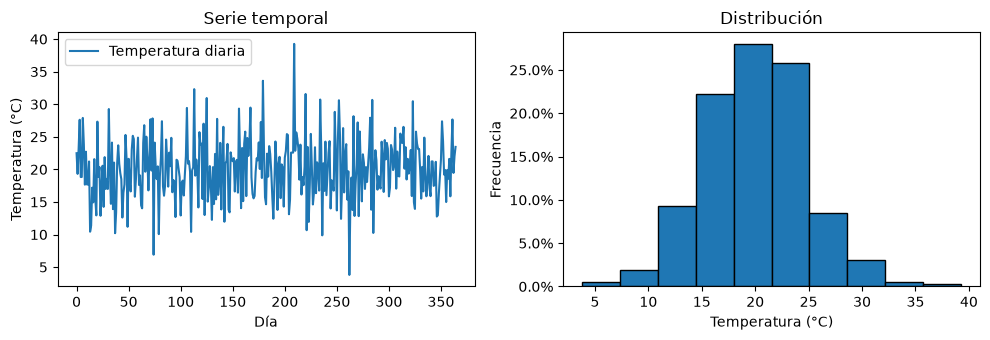

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter

np.random.seed(42)
temperatura = np.random.normal(20, 5, 365)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(temperatura, label="Temperatura diaria")
ax[0].set(xlabel="Día", ylabel="Temperatura (°C)", title="Serie temporal")
ax[0].legend()
# cada dato pesa 1/n, así las barras suman 1
ax[1].hist(temperatura, bins=10, edgecolor="black", weights=np.ones(len(temperatura)) / len(temperatura))
ax[1].yaxis.set_major_formatter(PercentFormatter(1))
ax[1].set(xlabel="Temperatura (°C)", ylabel="Frecuencia", title="Distribución")
plt.tight_layout()
plt.show()

## 2. Monte Carlo de un portfolio

Simular la evolución de un portfolio con retornos anuales normales. Probar combinaciones de retorno y volatilidad hasta encontrar alguna con pérdidas, y añadir una línea con la media de todos los escenarios.

retorno 0.07, volatilidad 0.04: 0% de escenarios con pérdidas
retorno 0.05, volatilidad 0.15: 16% de escenarios con pérdidas
retorno 0.03, volatilidad 0.25: 66% de escenarios con pérdidas


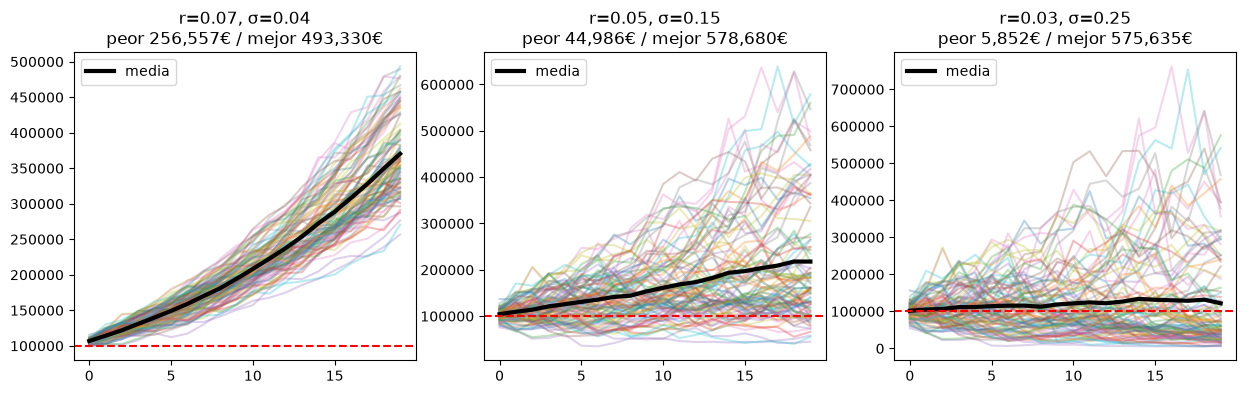

In [2]:
def simula_portfolio(inicial, retorno_anual, volatilidad_anual, tiempo_anios, simulaciones, ax):
    rng = np.random.default_rng(42)
    retornos = rng.normal(retorno_anual, volatilidad_anual, (tiempo_anios, simulaciones))
    valor = inicial * (1 + retornos).cumprod(axis=0)
    ax.plot(valor, alpha=0.3)
    ax.plot(valor.mean(axis=1), color="black", linewidth=3, label="media")
    ax.axhline(inicial, color="red", linestyle="--")
    ax.set_title(f"r={retorno_anual}, σ={volatilidad_anual}\npeor {valor[-1].min():,.0f}€ / mejor {valor[-1].max():,.0f}€")
    ax.legend()
    return (valor[-1] < inicial).mean()

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (r, v) in zip(ejes, ((0.07, 0.04), (0.05, 0.15), (0.03, 0.25))):
    perdidas = simula_portfolio(100_000, r, v, 20, 100, ax)
    print(f"retorno {r}, volatilidad {v}: {perdidas:.0%} de escenarios con pérdidas")
plt.show()

## 3. Mapa de calor de pases con `seaborn`

Con los datos abiertos de StatsBomb del partido España-Inglaterra (final de la Eurocopa, 14/07/2024), dibujar el mapa de calor del inicio y el final de los pases de España y compararlo con el de Inglaterra.

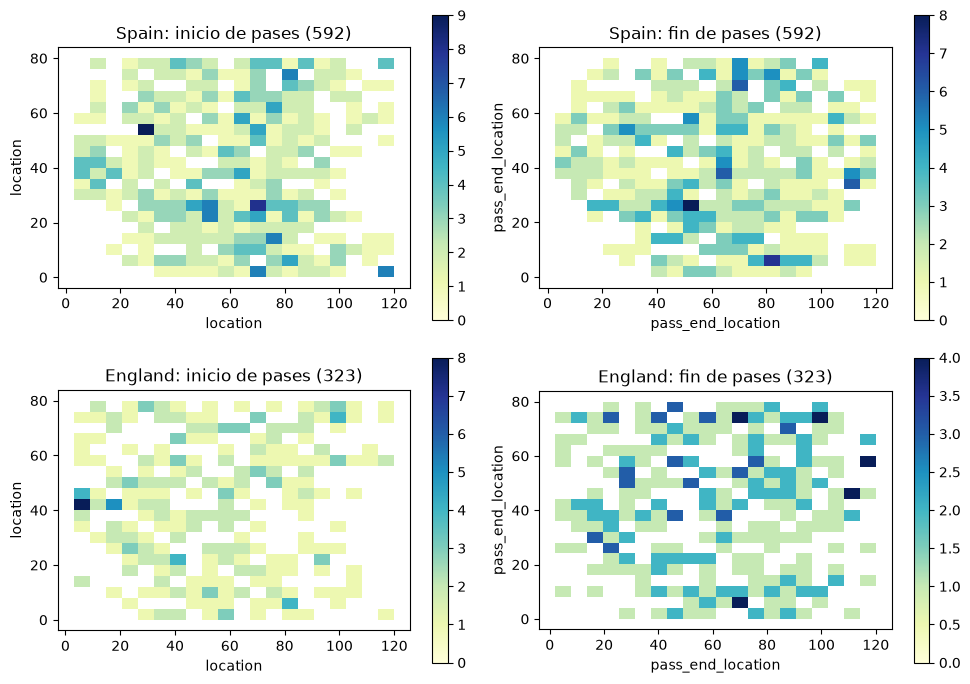

In [3]:
import seaborn as sns
import warnings
from statsbombpy import sb

with warnings.catch_warnings():
    # statsbombpy avisa de que se usan los datos abiertos sin credenciales
    warnings.simplefilter("ignore")
    eventos = sb.events(match_id=3943043)
pases = eventos[eventos["type"] == "Pass"]

fig, ejes = plt.subplots(2, 2, figsize=(10, 7))
for fila, equipo in zip(ejes, ("Spain", "England")):
    p = pases[pases["team"] == equipo]
    for ax, columna, titulo in zip(fila, ("location", "pass_end_location"), ("inicio", "fin")):
        sns.histplot(x=p[columna].str[0], y=p[columna].str[1], bins=(20, 20), cmap="YlGnBu", cbar=True, ax=ax)
        ax.set_aspect("equal", "box")
        ax.set_title(f"{equipo}: {titulo} de pases ({len(p)})")
plt.tight_layout()
plt.show()

## 4. Nube de palabras de *El Quijote*

Crear una nube de palabras de *El Quijote* ignorando las palabras vacías (artículos, preposiciones, conjunciones...) con el argumento `stopwords`.

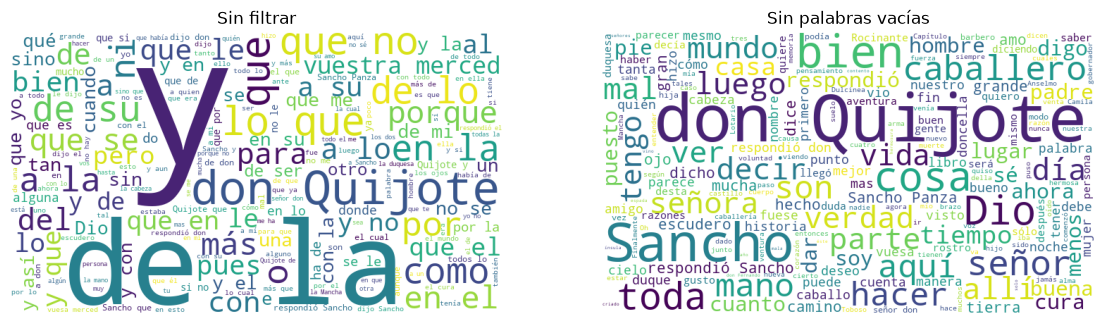

In [4]:
from urllib import request
from wordcloud import WordCloud

quijote = request.urlopen("https://raw.githubusercontent.com/ellibrodepython/50-ejemplos-python/main/ejemplos/43_quijote_wordcloud.txt").read().decode("utf-8")
vacias = set("""a al algo algún alguna algunas alguno algunos ante antes aquel aquella aquellas aquello aquellos así aun aunque cada como con contra cual cuando de del desde donde dos el él ella ellas ello ellos en entre era eran es esa esas ese eso esos esta está estaba estaban estas este esto estos fue fuera fueron ha había habían han hasta hay he la las le les lo los me mi mí mis mucho muy más nada ni no nos nosotros o os otra otras otro otros para pero poco por porque pues que qué quien se sea sean ser si sí sin sino sobre su sus tal también tan tanto te tenía tiene tiene todo todos tu tú un una uno unos vos y ya yo dijo así vuestra vuestro merced""".split())

fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (titulo, stop) in zip(ejes, (("Sin filtrar", set()), ("Sin palabras vacías", vacias))):
    ax.imshow(WordCloud(background_color="white", width=700, height=400, stopwords=stop, random_state=1).generate(quijote))
    ax.set_title(titulo)
    ax.axis("off")
plt.show()

## 5. Retorno diario de Apple

Descargar la cotización de Apple de 2020 con `yfinance`, calcular las medias móviles de 9 y 20 días con sus señales de compra y venta, y añadir una gráfica con el retorno diario en porcentaje.

count    252.00
mean       0.27
std        2.94
min      -12.86
25%       -1.04
50%        0.17
75%        1.71
max       11.98
Name: Retorno, dtype: float64


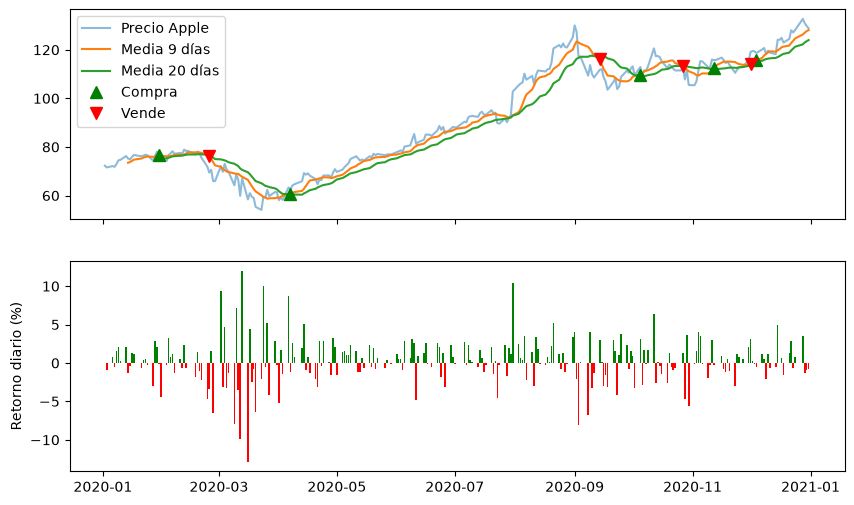

In [5]:
import yfinance as yf

apple = yf.download("AAPL", start="2020-01-01", end="2021-01-01", progress=False, multi_level_index=False)
apple["9_MA"] = apple["Close"].rolling(window=9).mean()
apple["20_MA"] = apple["Close"].rolling(window=20).mean()
apple["Position"] = np.where(apple["9_MA"] > apple["20_MA"], 1.0, 0.0)
apple["Position"] = apple["Position"].diff()
apple["Retorno"] = apple["Close"].pct_change() * 100

fig, (a, b) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a.plot(apple["Close"], label="Precio Apple", alpha=0.5)
a.plot(apple["9_MA"], label="Media 9 días")
a.plot(apple["20_MA"], label="Media 20 días")
a.plot(apple.index, np.where(apple["Position"] == 1, apple["9_MA"], np.nan), "^", markersize=8, color="g", label="Compra")
a.plot(apple.index, np.where(apple["Position"] == -1, apple["9_MA"], np.nan), "v", markersize=8, color="r", label="Vende")
a.legend()
b.bar(apple.index, apple["Retorno"], color=np.where(apple["Retorno"] >= 0, "green", "red"))
b.set_ylabel("Retorno diario (%)")
plt.show()
print(apple["Retorno"].describe().round(2))

## 6. Gráfica interactiva con `bokeh`

La aplicación de `bokeh` muestra una onda $a \sin(kx)$ con dos deslizadores. Añadir un botón de *reset* que restaure la amplitud y la frecuencia originales y ampliar los rangos de los deslizadores. Se guarda como script para ejecutarlo con `bokeh serve interactivo_bokeh.py`; aquí se comprueba su lógica sin servidor.

In [6]:
codigo = '''
import numpy as np
from bokeh.io import curdoc
from bokeh.layouts import column
from bokeh.models import Button, ColumnDataSource, Slider
from bokeh.plotting import figure

N = 200
AMPLITUD, FRECUENCIA = 1.0, 1.0
x = np.linspace(0, 4 * np.pi, N)
source = ColumnDataSource(data=dict(x=x, y=AMPLITUD * np.sin(FRECUENCIA * x)))
plot = figure(height=400, width=400, y_range=[-10.5, 10.5])
plot.line("x", "y", source=source, line_width=3, line_alpha=0.6)

amplitud = Slider(title="amplitud", value=AMPLITUD, start=-10.0, end=10.0, step=0.1)
frecuencia = Slider(title="frecuencia", value=FRECUENCIA, start=0.1, end=20.1, step=0.1)
reset = Button(label="Reset")

def update_data(attrname, old, new):
    source.data = dict(x=x, y=amplitud.value * np.sin(frecuencia.value * x))

def reset_valores():
    amplitud.value, frecuencia.value = AMPLITUD, FRECUENCIA

for w in (amplitud, frecuencia):
    w.on_change("value", update_data)
reset.on_click(reset_valores)
curdoc().add_root(column(amplitud, frecuencia, reset, plot, width=800))
'''
with open("interactivo_bokeh.py", "w", encoding="utf-8") as f:
    f.write(codigo)

app = {}
exec(codigo, app)
app["amplitud"].value, app["frecuencia"].value = 7.5, 15.0
app["update_data"](None, None, None)
print(app["source"].data["y"].max().round(2), app["amplitud"].end, app["frecuencia"].end)
app["reset_valores"]()
app["update_data"](None, None, None)
print(app["amplitud"].value, app["frecuencia"].value, app["source"].data["y"].max().round(2))

7.5 10.0 20.1
1.0 1.0 1.0
